# Estimating spread and volatility from price ranges

This Julia notebook follows the same experiment, equations, sample sizes, parameters, and decision rules as its Python counterpart. Random experiments use the displayed integer seeds with Julia’s `Xoshiro` generator, so their realized samples differ from NumPy. Public observations use the same stated data sources. Figures use the requested dark theme, and Julia outputs are saved under `outputs/julia`. The finite-sample study draws its 1,440 child seeds from `Xoshiro(20260926)` and saves every Gaussian innovation, observed trade side, and resulting OHLC bar so the calculation can be repeated. The published equation is compared with the current library calculation.

$\beta_t$ averages the sum of two adjacent squared one-bar ranges, while $\gamma_t$ measures one range over the same two bars:

$$
\beta_t=\frac{1}{w}\sum_{i=t-w+1}^{t}
\left[
\log^2\!\left(\frac{H_i}{L_i}\right)
+\log^2\!\left(\frac{H_{i-1}}{L_{i-1}}\right)
\right],
\qquad
\gamma_t=\log^2\!\left(
\frac{\max(H_t,H_{t-1})}{\min(L_t,L_{t-1})}
\right).
$$

Here, $H_i$ and $L_i$ are the observed high and low in bar $i$; $w$ is the rolling averaging length. $\beta_t$ is the smoothed two-bar range sum; $\gamma_t$ is the squared two-bar combined range; $\log$ is the natural logarithm.

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("11_market_microstructure");
using CSV, Printf
using RiskLabAI.Features: alpha_estimates,bekker_parkinson_volatility_estimates,beta_estimates,corwin_schultz_estimator,edge_estimator,gamma_estimates,sigma_estimates
raw = load_binance()
data_path = dataset_path("binance_btcusdt")
@assert isfile(data_path)
minute = select(raw,:time,"Open"=>:open,"High"=>:high,"Low"=>:low,:close,:volume,:quote_volume,:trades)

function make_bars(period)
    return combine(groupby(transform(minute,:time=>(time->floor.(time,period))=>:time),:time;sort=true),:open=>first=>:open,:high=>maximum=>:high,:low=>minimum=>:low,:close=>last=>:close,:volume=>sum=>:volume,:quote_volume=>sum=>:quote_volume,:trades=>sum=>:trades)
end

function rolling_mean(values,window)
    result = fill(NaN,length(values))
    for ending in window:length(values)
        sample = values[ending-window+1:ending]
        all(isfinite,sample) && (result[ending]=mean(sample))
    end
    return result
end

function calendar_ticks(times;step=Day(6))
    ticks = collect(DateTime(Date(first(times))):step:DateTime(Date(last(times))))
    return Dates.value.(ticks),Dates.format.(ticks,dateformat"mm-dd")
end

function spread_values(sample)
    magnitude = edge_estimator(sample.open,sample.high,sample.low,sample.close)
    signed = edge_estimator(sample.open,sample.high,sample.low,sample.close;sign=true)
    cs = mean(filter(isfinite,corwin_schultz_estimator(sample.high,sample.low,1)))
    return (magnitude=magnitude,zero_floor=max(signed,0.),signed=signed,cs=cs)
end

bars_15 = make_bars(Minute(15));


## Two Range Scales

Row,Component,Mean,Median,90th percentile,Zero share
,String,Float64,Float64,Float64,Float64
1,Beta,0.000360869,0.000270226,0.000720891,0.0
2,Gamma,0.000357338,0.000181337,0.000710939,0.0
3,Alpha,0.0102354,0.00786836,0.0252952,0.305903
4,"Spread, basis points",102.349,78.6832,252.939,0.305903


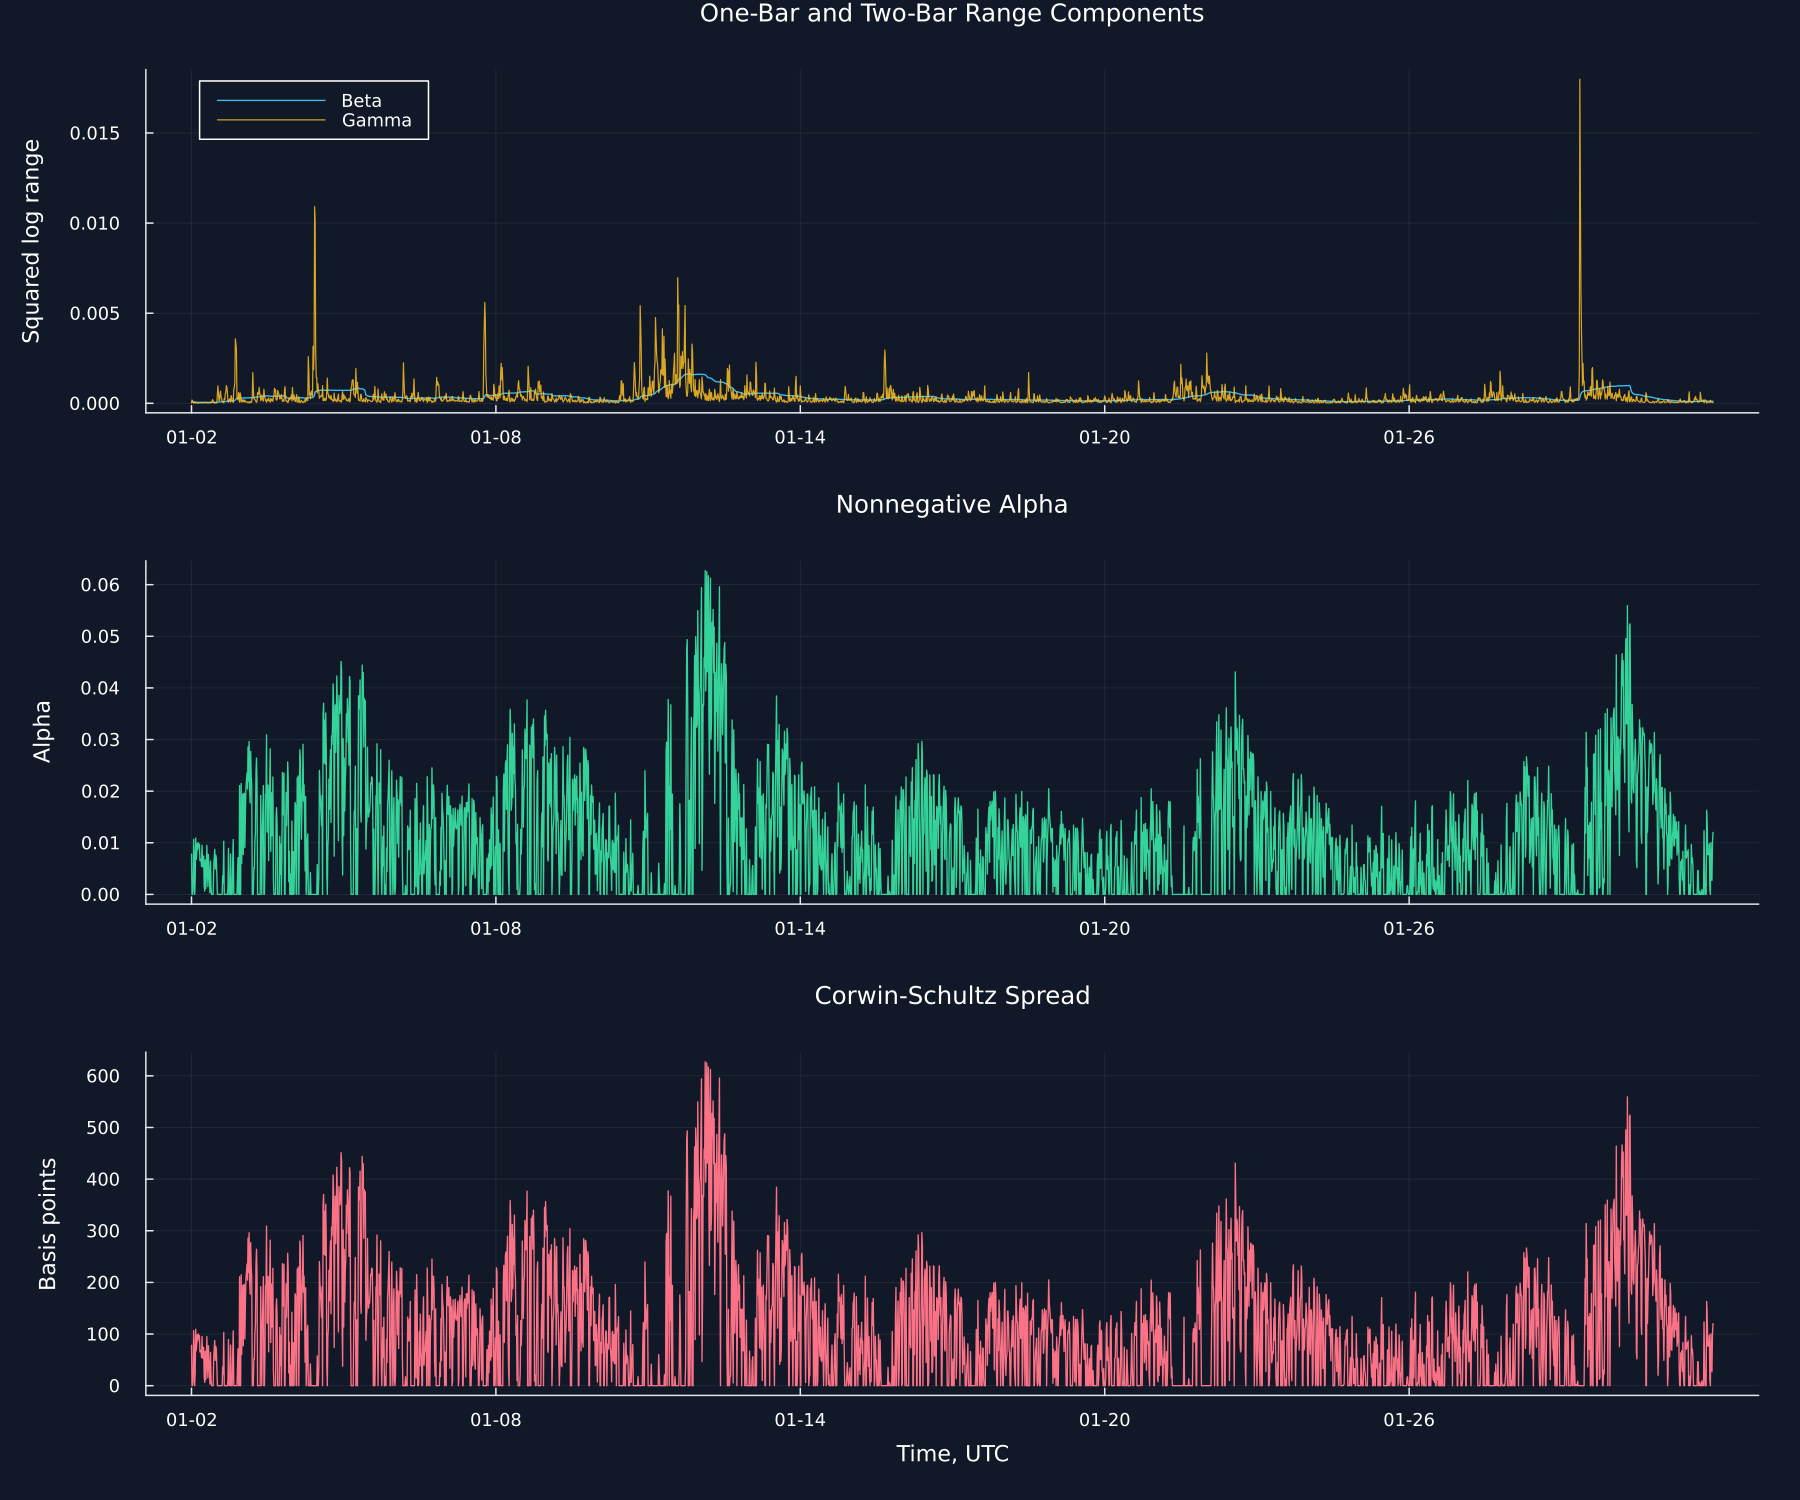

In [2]:
window_span = 96
public_high,public_low = bars_15.high,bars_15.low
beta = beta_estimates(public_high,public_low,window_span)
gamma = gamma_estimates(public_high,public_low)
alpha = alpha_estimates(beta,gamma)
spread = corwin_schultz_estimator(public_high,public_low,window_span)
valid = isfinite.(beta).&isfinite.(gamma).&isfinite.(alpha).&isfinite.(spread)
component_frame = DataFrame(time=bars_15.time[valid],Beta=beta[valid],Gamma=gamma[valid],Alpha=alpha[valid],Spread=spread[valid])
component_values = [component_frame.Beta,component_frame.Gamma,component_frame.Alpha,10000component_frame.Spread]
corwin_schultz_components = DataFrame("Component"=>["Beta","Gamma","Alpha","Spread, basis points"],"Mean"=>mean.(component_values),"Median"=>median.(component_values),"90th percentile"=>[quantile(values,.9) for values in component_values],"Zero share"=>[mean(values.==0) for values in component_values])
save_table(corwin_schultz_components,paths,"corwin_schultz_components";caption="Public Corwin-Schultz component summaries for a 96-bar averaging length.",label="tab:chapter10-corwin-schultz-components")
p1 = plot(component_frame.time,component_frame.Beta;color=palette.cyan,linewidth=.9,label="Beta",title="One-Bar and Two-Bar Range Components",ylabel="Squared log range",xticks=calendar_ticks(component_frame.time))
plot!(p1,component_frame.time,component_frame.Gamma;color=palette.amber,linewidth=.8,alpha=.85,label="Gamma")
p2 = plot(component_frame.time,component_frame.Alpha;color=palette.green,linewidth=.9,label=false,title="Nonnegative Alpha",ylabel="Alpha",xticks=calendar_ticks(component_frame.time))
p3 = plot(component_frame.time,10000component_frame.Spread;color=palette.rose,linewidth=.9,label=false,title="Corwin-Schultz Spread",xlabel="Time, UTC",ylabel="Basis points",xticks=calendar_ticks(component_frame.time))
save_figure(plot(p1,p2,p3;layout=(3,1),size=(1200,1000),left_margin=6Plots.mm),paths,"corwin_schultz_components")
save_data(DataFrame(time=bars_15.time,beta=beta,gamma=gamma,alpha=alpha,spread=spread),paths,"corwin_schultz_paths");


## Spread from Alpha

The estimator removes a two-bar movement term from the average one-bar ranges, then maps the nonnegative remainder to a proportional spread:

$$
d=3-2\sqrt{2},
\qquad
\alpha_t=\max\!\left\{0,
\frac{(\sqrt{2}-1)\sqrt{\beta_t}}{d}
-\sqrt{\frac{\gamma_t}{d}}
\right\},
\qquad
\widehat S_t=\frac{2(e^{\alpha_t}-1)}{1+e^{\alpha_t}}.
$$

Here, $d$ is a fixed constant; $\beta_t$ and $\gamma_t$ are the two range measurements defined above. $\alpha_t$ is the nonnegative intermediate value; $e$ is the exponential base; $\widehat S_t$ is the estimated proportional spread.

In [3]:
sensitivity_rows = NamedTuple[]
sensitivity_paths = DataFrame()
for current_window in [12,24,48,96,192]
    current_beta = beta_estimates(public_high,public_low,current_window)
    current_gamma = gamma_estimates(public_high,public_low)
    current_alpha = alpha_estimates(current_beta,current_gamma)
    current_spread = corwin_schultz_estimator(public_high,public_low,current_window)
    valid = isfinite.(current_beta).&isfinite.(current_gamma).&isfinite.(current_alpha).&isfinite.(current_spread)
    push!(sensitivity_rows,(window=current_window,available=sum(valid),beta=median(current_beta[valid]),gamma=median(current_gamma[valid]),spread_median=10000median(current_spread[valid]),spread_mean=10000mean(current_spread[valid]),zero=mean(current_spread[valid].==0)))
    append!(sensitivity_paths,DataFrame(window=fill(current_window,nrow(bars_15)),time=bars_15.time,beta=current_beta,gamma=current_gamma,alpha=current_alpha,spread=current_spread);cols=:union)
end
estimator_window_sensitivity = DataFrame(sensitivity_rows)
rename!(estimator_window_sensitivity,["Averaging bars","Available estimates","Median beta","Median gamma","Median spread, basis points","Mean spread, basis points","Zero spread share"])
save_table(estimator_window_sensitivity,paths,"estimator_window_sensitivity";caption="Corwin-Schultz estimates across five averaging lengths.",label="tab:chapter10-estimator-window-sensitivity")
save_data(sensitivity_paths,paths,"corwin_schultz_sensitivity_paths");


Row,Averaging bars,Available estimates,Median beta,Median gamma,"Median spread, basis points","Mean spread, basis points",Zero spread share
,Int64,Int64,Float64,Float64,Float64,Float64,Float64
1,12,2964,0.000216892,0.000175021,44.0942,76.9141,0.352227
2,24,2952,0.000227223,0.000176005,54.2883,85.4049,0.333333
3,48,2928,0.000235629,0.000176753,66.2159,92.2668,0.323087
4,96,2880,0.000270226,0.000181337,78.6832,102.349,0.305903
5,192,2784,0.000292921,0.000183388,94.7731,117.139,0.286279


## Reconciling the published formula with the library

The checked published equation combines the one-bar and two-bar ranges to estimate volatility after separating the spread component:

$$
k_2=\sqrt{\frac{8}{\pi}},
\qquad
\widehat\sigma_{BP,t}
=\max\!\left\{0,
\frac{(2^{-1/2}-1)\sqrt{\beta_t}}{k_2d}
+\sqrt{\frac{\gamma_t}{k_2^2d}}
\right\}.
$$

Here, $k_2$ and $d=3-2\sqrt{2}$ are constants; $\beta_t$ and $\gamma_t$ are the range measurements. $\widehat\sigma_{BP,t}$ is the published Bekker-Parkinson volatility estimate; $\pi$ is the circle constant; the maximum floors negative values at zero.

This is the calculation in the current public RiskLabAI function, shown separately because its first term differs from the checked published equation:

$$
\widehat\sigma_{\mathrm{lib},t}
=\max\!\left\{0,
\frac{(\sqrt{2}-1)\sqrt{\beta_t}}{d}
+\sqrt{\frac{\gamma_t}{k_2^2d}}
\right\}.
$$

Here, $\widehat\sigma_{\mathrm{lib},t}$ is the current library output; $\beta_t,\gamma_t,k_2$ and $d$ have the definitions above. $\sqrt{2}-1$ is positive, whereas the published coefficient $2^{-1/2}-1$ is negative and is divided by $k_2.$

Row,Check,Published equation,Current library
,String,String,String
1,First beta coefficient,(2^(-1/2)-1)/(k2 d),(sqrt(2)-1)/d
2,First beta term sign,Negative,Positive
3,Division by k2 in first term,Yes,No
4,First valid fixture value,0.014831,0.112169
5,Public median,0.002046,0.060890


Row,Quantity,10th percentile,Median,90th percentile,Mean
,String,Float64,Float64,Float64,Float64
1,"Corwin-Schultz spread, basis points",0.0,78.6832,252.939,102.349
2,Published volatility,0.0,0.00204609,0.0196371,0.00688727
3,Current library volatility,0.0419488,0.0608902,0.101877,0.0673995
4,Library minus published volatility,0.0388791,0.0550426,0.0899673,0.0605122


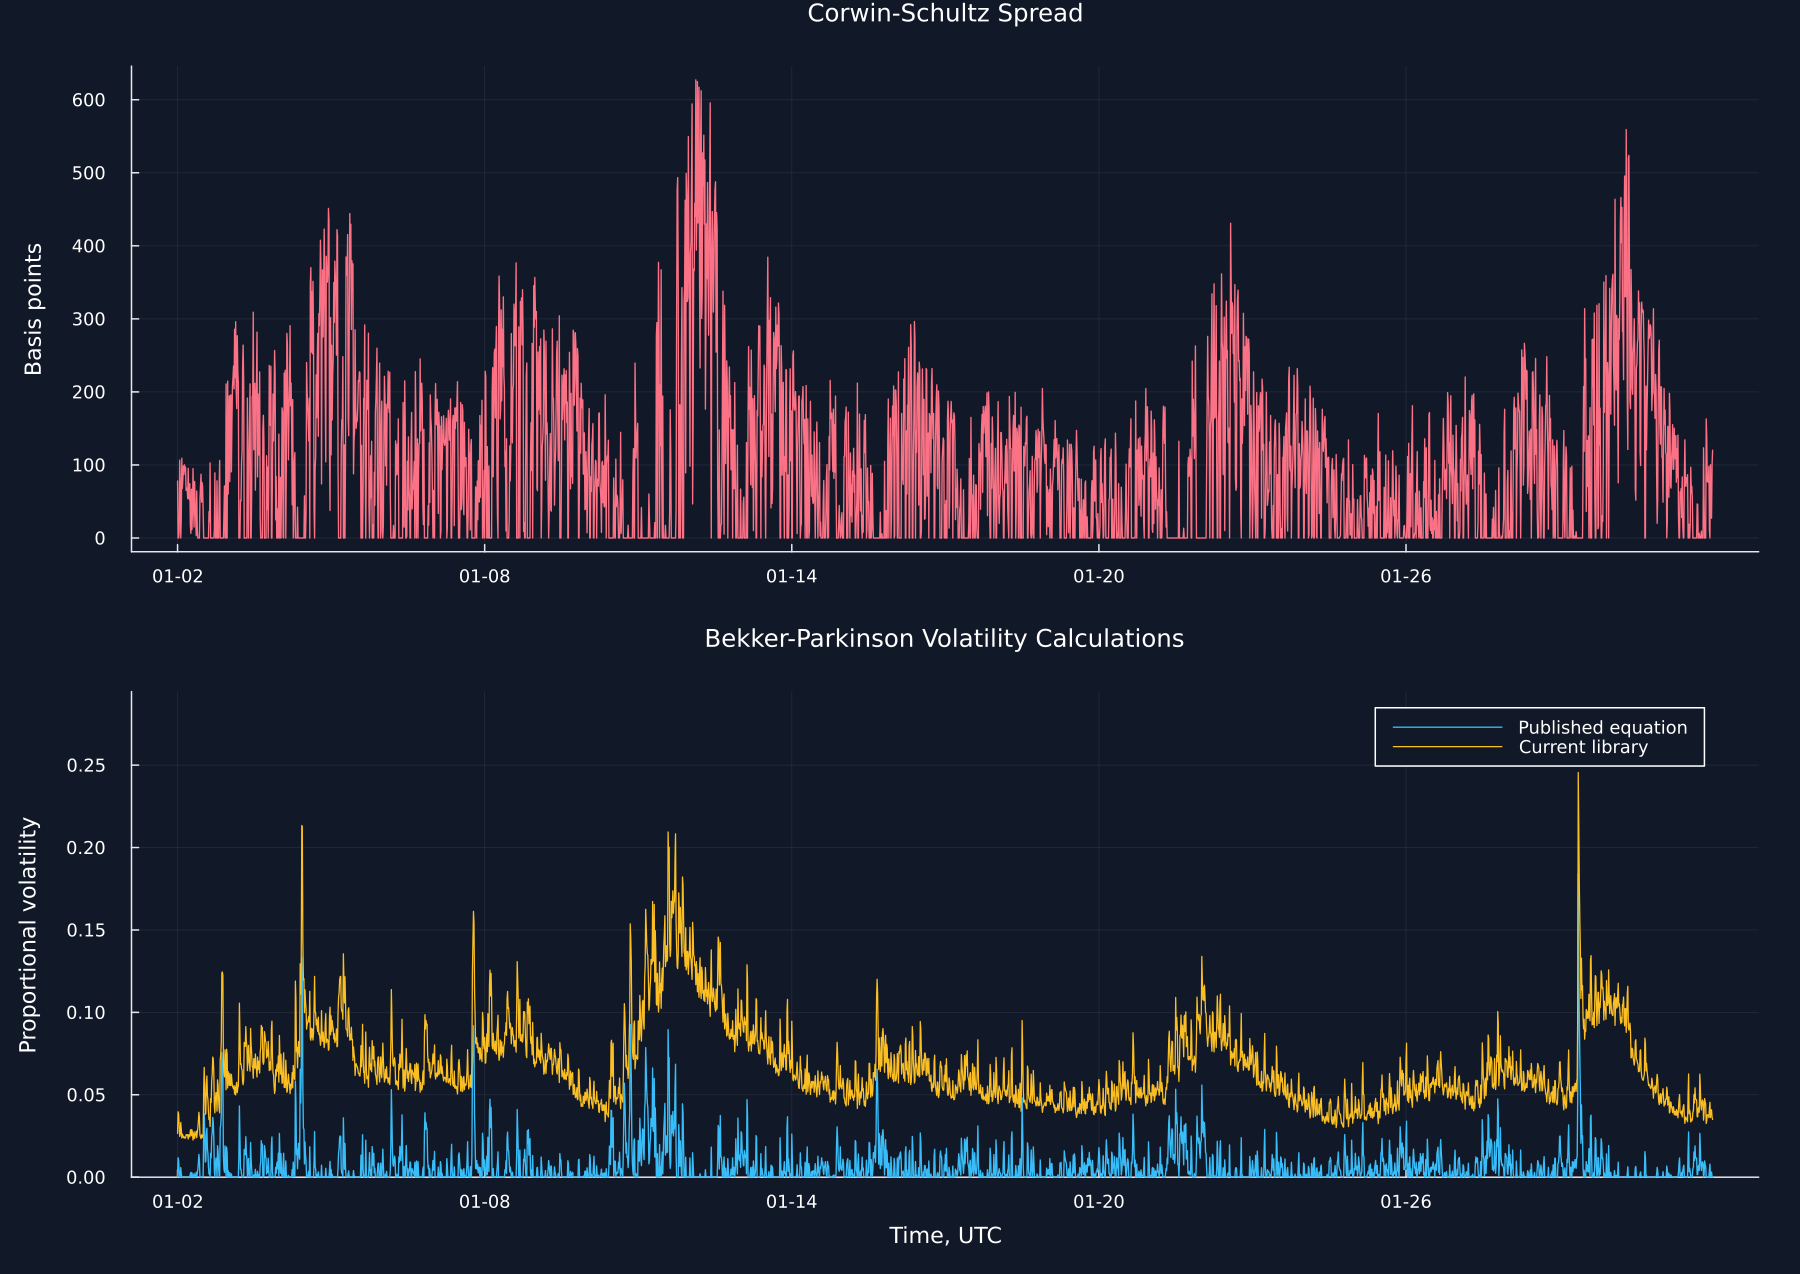

In [4]:
d_constant = 3-2sqrt(2)
k2_constant = sqrt(8/pi)
published_sigma(beta,gamma) = max.((2^(-.5)-1).*sqrt.(beta)./(k2_constant*d_constant).+sqrt.(gamma./(k2_constant^2*d_constant)),0)
published_volatility = published_sigma(beta,gamma)
library_volatility = sigma_estimates(beta,gamma)
wrapper_volatility = bekker_parkinson_volatility_estimates(public_high,public_low,window_span)
valid = isfinite.(spread).&isfinite.(published_volatility).&isfinite.(library_volatility)
volatility_frame = DataFrame("time"=>bars_15.time[valid],"Spread"=>spread[valid],"Published volatility"=>published_volatility[valid],"Library volatility"=>library_volatility[valid])
fixture_high = [10.1,10.3,10.2,10.4,10.5]
fixture_low = [9.9,10.1,10.,10.2,10.3]
fixture_beta = beta_estimates(fixture_high,fixture_low,2)
fixture_gamma = gamma_estimates(fixture_high,fixture_low)
fixture_published = published_sigma(fixture_beta,fixture_gamma)
fixture_library = sigma_estimates(fixture_beta,fixture_gamma)
first_valid = findfirst(isfinite,fixture_published)
bekker_parkinson_formula_audit = DataFrame("Check"=>["First beta coefficient","First beta term sign","Division by k2 in first term","First valid fixture value","Public median"],"Published equation"=>["(2^(-1/2)-1)/(k2 d)","Negative","Yes",@sprintf("%.6f",fixture_published[first_valid]),@sprintf("%.6f",median(volatility_frame[!,"Published volatility"]))],"Current library"=>["(sqrt(2)-1)/d","Positive","No",@sprintf("%.6f",fixture_library[first_valid]),@sprintf("%.6f",median(volatility_frame[!,"Library volatility"]))])
save_table(bekker_parkinson_formula_audit,paths,"bekker_parkinson_formula_audit";caption="Checked published equation and current public library calculation.",label="tab:chapter10-bekker-parkinson-formula-audit")
volatility_values = [10000volatility_frame.Spread,volatility_frame[!,"Published volatility"],volatility_frame[!,"Library volatility"],volatility_frame[!,"Library volatility"].-volatility_frame[!,"Published volatility"]]
spread_volatility_quantiles = DataFrame("Quantity"=>["Corwin-Schultz spread, basis points","Published volatility","Current library volatility","Library minus published volatility"],"10th percentile"=>[quantile(values,.1) for values in volatility_values],"Median"=>median.(volatility_values),"90th percentile"=>[quantile(values,.9) for values in volatility_values],"Mean"=>mean.(volatility_values))
save_table(spread_volatility_quantiles,paths,"spread_volatility_quantiles";caption="Public spread and volatility quantiles.",label="tab:chapter10-spread-volatility-quantiles")
p1 = plot(volatility_frame.time,10000volatility_frame.Spread;color=palette.rose,linewidth=.9,label=false,title="Corwin-Schultz Spread",ylabel="Basis points",xticks=calendar_ticks(volatility_frame.time))
p2 = plot(volatility_frame.time,volatility_frame[!,"Published volatility"];color=palette.cyan,linewidth=.9,label="Published equation",title="Bekker-Parkinson Volatility Calculations",xlabel="Time, UTC",ylabel="Proportional volatility",xticks=calendar_ticks(volatility_frame.time),legend=:topright,ylims=(0,1.2maximum(volatility_frame[!,"Library volatility"])))
plot!(p2,volatility_frame.time,volatility_frame[!,"Library volatility"];color=palette.amber,linewidth=.85,label="Current library")
save_figure(plot(p1,p2;layout=(2,1),size=(1200,850),left_margin=6Plots.mm),paths,"spread_volatility_estimates")
save_data(DataFrame(time=bars_15.time,published=published_volatility,library=library_volatility,wrapper=wrapper_volatility),paths,"bekker_parkinson_paths");
save_data(DataFrame(high=fixture_high,low=fixture_low,beta=fixture_beta,gamma=fixture_gamma,published=fixture_published,library=fixture_library),paths,"bekker_parkinson_fixture");


## Tests

In [5]:
manual_log_range_squared = log.(public_high./public_low).^2
manual_beta = rolling_mean([NaN;manual_log_range_squared[1:end-1].+manual_log_range_squared[2:end]],window_span)
manual_gamma = [NaN;log.(max.(public_high[1:end-1],public_high[2:end])./min.(public_low[1:end-1],public_low[2:end])).^2]
manual_alpha = max.((sqrt(2)-1).*sqrt.(manual_beta)./d_constant.-sqrt.(manual_gamma./d_constant),0)
manual_spread = 2 .* (exp.(manual_alpha).-1)./(1 .+exp.(manual_alpha))
@assert nrow(component_frame)==nrow(bars_15)-window_span
@assert filter(isfinite,beta)≈filter(isfinite,manual_beta)
@assert filter(isfinite,gamma)≈filter(isfinite,manual_gamma)
@assert filter(isfinite,alpha)≈filter(isfinite,manual_alpha)
@assert filter(isfinite,spread)≈filter(isfinite,manual_spread)
@assert filter(isfinite,library_volatility)≈filter(isfinite,wrapper_volatility)
@assert all(filter(isfinite,alpha).>=0)
@assert all(0 .<=filter(isfinite,spread).<=2)
@assert issorted(estimator_window_sensitivity[!,"Available estimates"];rev=true)
@assert all(0 .<=estimator_window_sensitivity[!,"Zero spread share"].<=1)
@assert !(filter(isfinite,fixture_published)≈filter(isfinite,fixture_library))
@assert !(volatility_frame[!,"Published volatility"]≈volatility_frame[!,"Library volatility"])
@assert isapprox(fixture_published[first_valid],.014830915437167;atol=1e-12)
@assert isapprox(fixture_library[first_valid],.112169310280388;atol=1e-12)
@assert all(volatility_frame[!,"Published volatility"].>=0)
@assert all(volatility_frame[!,"Library volatility"].>=0)
@assert all(volatility_frame[!,"Library volatility"].>volatility_frame[!,"Published volatility"])
@assert isfile(joinpath(paths.figures,"corwin_schultz_components.pdf"))
@assert isfile(joinpath(paths.figures,"spread_volatility_estimates.pdf"))
@assert isfile(joinpath(paths.tables,"corwin_schultz_components.tex"))
@assert isfile(joinpath(paths.tables,"estimator_window_sensitivity.tex"))
@assert isfile(joinpath(paths.tables,"bekker_parkinson_formula_audit.tex"))
@assert isfile(joinpath(paths.tables,"spread_volatility_quantiles.tex"))
